# The Model That Lost Alone and Won the Ensemble
## An LLM as an orthogonal ranker for survival prediction

A case study: the ANNITIA 2026 challenge. Predict major hepatic events and all-cause death
from irregular longitudinal records of MASLD patients (metabolic dysfunction-associated
steatotic liver disease).

*Every cell that runs here uses a synthetic cohort or our own aggregate scores. No challenge
record appears in this notebook, and a guard enforces that.*

In [1]:
import sys, csv, io, contextlib
from IPython.display import display
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr, binomtest
from sksurv.metrics import concordance_index_censored
ROOT = Path.cwd().parent if Path.cwd().name == "talk" else Path.cwd()
for p in ("scripts", "talk"):
    sys.path.insert(0, str(ROOT / p))
import guard; guard.install()                       # refuse to open any challenge file
import synthetic as S
from annitia_helm_submit import serialize_patient, _fib4, _traj, SCORE_PROMPT_HEPATIC
from helm_gptoss_blend_v2 import _rank01
from push_score_allout import fit_xgb, fit_cat, transform_matrices, rank_blend
DATA = ROOT / "talk" / "data"
def csv_rows(name):
    path = DATA / name
    if not path.is_file():
        return []
    with open(path, newline="") as f:
        return list(csv.DictReader(f))
def cidx(event, time, score):
    return concordance_index_censored(np.asarray(event, bool), np.asarray(time, float), score)[0]
def ystruct(event, time):
    return np.array(list(zip(event, time)), dtype=[("event", bool), ("time", float)])
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.spines.top": False, "axes.spines.right": False})
C = S.cohort(2000, seed=0)                          # the synthetic cohort used throughout

## The argument, in one sentence
A reasoning LLM that reads a patient's history as clinical text is a **weak** survival model
on its own. On the leaderboard it seemed to improve a strong tabular ensemble, because it makes
**different mistakes**. This talk shows why that was plausible, and how a leak-free
replication overturned it.

1. **Objective:** the metric only sees order, so we blend ranks.
2. **Data:** wide, irregular, censored records.
3. **Tabular base:** XGBoost AFT and CatBoost SurvivalAft.
4. **Serializing a patient:** from a wide row to a clinical summary.
5. **Why a weak ranker helps:** error correlation is the lever.
6. **Checking orthogonality** before spending API calls.
7. **The two-stage blend** we submitted.
8. **False-positive gates:** five criteria, applied to our own decisions.
9. **Limits** and honest reporting.

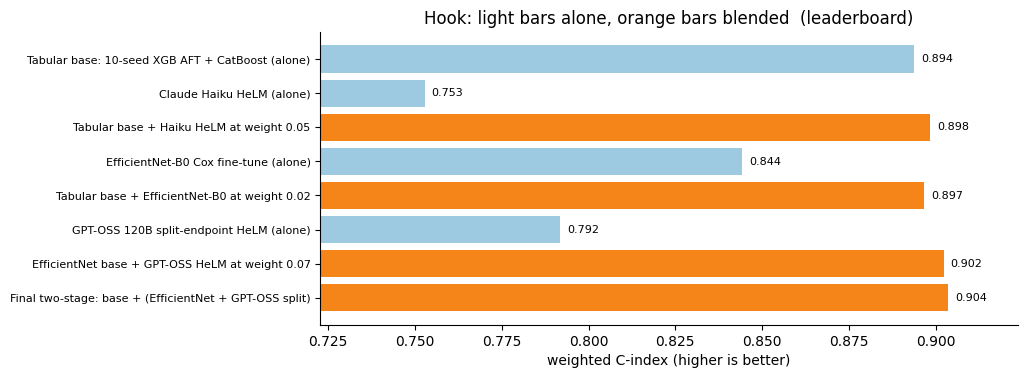

In [2]:
cv, lb = csv_rows("cv_scores.csv"), csv_rows("leaderboard.csv")
if lb:                                              # our own leaderboard milestones
    labels, vals, src = [r["submission"] for r in lb], [float(r["public_score"]) for r in lb], "leaderboard"
elif cv:                                            # our measured cross-validation numbers
    labels, vals, src = [r["model"] for r in cv], [float(r["weighted"]) for r in cv], "10-fold CV"
else:                                               # fallback: the same story on the synthetic cohort
    tab, llm = S.rankers(C.true_hep.to_numpy(), seed=1, shared=0.1)
    ev, t = C.hep_event, C.hep_time
    labels = ["tabular (alone)", "LLM (alone)", "tabular + LLM ranks"]
    vals = [cidx(ev, t, tab), cidx(ev, t, llm), cidx(ev, t, 0.8 * _rank01(tab) + 0.2 * _rank01(llm))]
    src = "synthetic cohort"
fig, ax = plt.subplots(figsize=(9, 3.8))
colours = ["#9ecae1" if "(alone)" in l else "#f58518" for l in labels]
ax.barh(labels[::-1], vals[::-1], color=colours[::-1])
for i, v in enumerate(vals[::-1]):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlim(min(vals) - 0.03, max(vals) + 0.02); ax.set_xlabel("weighted C-index (higher is better)")
ax.tick_params(axis="y", labelsize=8)
ax.set_title(f"Hook: light bars alone, orange bars blended  ({src})")
plt.show()

On the leaderboard, GPT-OSS alone scored **0.792**, far below the tabular base at **0.894**.
Blended at a small rank weight, it gave this pipeline's best score, **0.904**. Section 8 tests
whether that gain was real.

## 1 · Objective: the metric only sees order
**Score = 0.7 × C-index(hepatic) + 0.3 × C-index(death).**

Harrell's C-index asks one question of every comparable pair: did the patient with the
earlier event get the higher risk? Scale, calibration and units are invisible to it.

In [3]:
tab, llm = S.rankers(C.true_hep.to_numpy(), seed=1, shared=0.1)
ev, t = C.hep_event, C.hep_time
print(f"C-index of a score            {cidx(ev, t, tab):.4f}")
print(f"C-index of exp(score)         {cidx(ev, t, np.exp(tab)):.4f}   (any monotone map: identical)")

# Averaging raw scores lets the wider scale win. Averaging ranks weighs both fairly.
raw = 0.5 * tab + 0.5 * llm                          # llm lives on 0-100, tab on about -3..3
print(f"\nraw 50/50 average    {cidx(ev, t, raw):.4f}   <- mostly the LLM, by scale alone")
print(f"rank 50/50 average   {cidx(ev, t, rank_blend({'tab': tab, 'llm': llm}, {'tab': .5, 'llm': .5})):.4f}")

C-index of a score            0.7926
C-index of exp(score)         0.7926   (any monotone map: identical)

raw 50/50 average    0.7606   <- mostly the LLM, by scale alone
rank 50/50 average   0.7884


**Transfer:** when the metric is a ranking metric, blend ranks. Then models with
incompatible outputs (log-times, hazards, 0-100 LLM scores) can be combined safely.

## 2 · The data: wide, irregular and censored
One row per patient, up to 22 visits, each with biomarkers such as ALT, platelets, FibroScan
stiffness and FibroTest. Visits are irregular, non-invasive tests are often missing, and most
patients never have the event (right censoring).

### What each column means
From the challenge data dictionary, lightly edited. Visit columns carry a suffix `_v1` to `_v22`.

| Group | Variables | Meaning |
|---|---|---|
| Baseline | `gender`, `T2DM`, `Hypertension`, `Dyslipidaemia` | biological sex (coded), type 2 diabetes, hypertension, dyslipidaemia |
| Baseline | `bariatric_surgery`, `bariatric_surgery_age` | bariatric surgery, and age at surgery |
| Per visit | `Age`, `BMI` | age in years, body mass index |
| Liver labs | `alt`, `ast`, `ggt`, `bilirubin`, `plt` | ALAT (TGP), ASAT (TGO), gamma-GT, bilirubin, platelets |
| Metabolic labs | `gluc_fast`, `triglyc`, `chol` | fasting glucose, triglycerides, cholesterol |
| Non-invasive tests | `fibs_stiffness_med_BM_1` | median liver stiffness (FibroScan) |
| Non-invasive tests | `fibrotest_BM_2` | fibrosis probability score (FibroTest) |
| Non-invasive tests | `aixp_aix_result_BM_3` | Aixplorer liver stiffness |
| Outcomes | `evenements_hepatiques_majeurs`, `evenements_hepatiques_age_occur` | composite liver-related outcome, and age at the first event |
| Outcomes | `death`, `death_age_occur` | all-cause death, and age at death |

Both targets are risk scores to rank: `risk_hepatic_event` and `risk_death`. Event times are
ages, so follow-up runs from the first visit's age to the event or last-visit age.

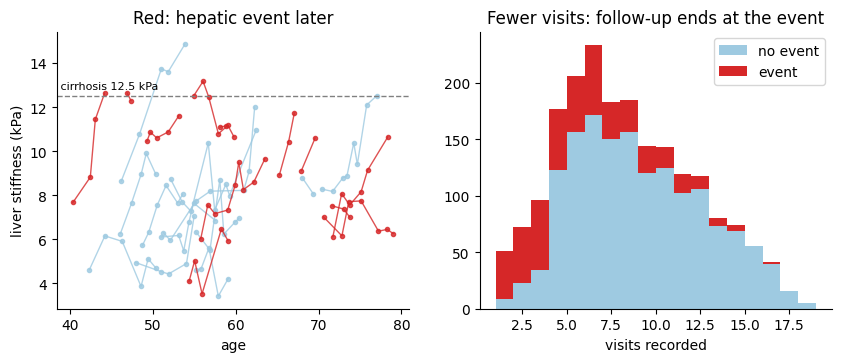

hepatic events 23.1% | deaths 14.7% | censored for both 62.2%


In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
rng = np.random.default_rng(3)
for ev_flag, colour in ((False, "#9ecae1"), (True, "#d62728")):
    for i in rng.choice(np.flatnonzero(C.hep_event == ev_flag), 12, replace=False):
        r = C.iloc[i]
        ages = [r.get(f"Age_v{v}") for v in range(1, 23)]
        kpa = [r.get(f"fibs_stiffness_med_BM_1_v{v}") for v in range(1, 23)]
        pts = [(a, k) for a, k in zip(ages, kpa) if pd.notna(a) and pd.notna(k)]
        if pts:
            a1.plot(*zip(*pts), marker=".", color=colour, lw=1, alpha=0.8)
a1.axhline(12.5, ls="--", c="grey", lw=1); a1.text(a1.get_xlim()[0], 12.8, " cirrhosis 12.5 kPa", fontsize=8)
a1.set_xlabel("age"); a1.set_ylabel("liver stiffness (kPa)"); a1.set_title("Red: hepatic event later")
visits = C.filter(regex=r"^Age_v\d+$").notna().sum(axis=1)
a2.hist([visits[~C.hep_event], visits[C.hep_event]], bins=range(1, 20), label=["no event", "event"],
        color=["#9ecae1", "#d62728"], stacked=True)
a2.set_xlabel("visits recorded"); a2.legend(); a2.set_title("Fewer visits: follow-up ends at the event")
plt.show()
print(f"hepatic events {C.hep_event.mean():.1%} | deaths {C.death_event.mean():.1%} | censored for both "
      f"{(~C.hep_event & ~C.death_event).mean():.1%}")

**Leakage trap:** visit count and follow-up length encode the outcome. The pipeline drops these
label proxies and masks visits after the event before building features.

## 3 · The tabular base: accelerated failure time boosting
XGBoost AFT and CatBoost SurvivalAft, rank blended per endpoint and averaged over 10 seeds.
The real features are trajectory summaries (first, last, slope, volatility), clinical scores
such as FIB-4 and APRI, and missingness patterns. Here is a trimmed version on the synthetic cohort.

In [5]:
PREFIXES = ("Age", "BMI", "alt", "ast", "ggt", "plt", "bilirubin", "gluc_fast", "triglyc",
            "fibs_stiffness_med_BM_1", "fibrotest_BM_2")
def features(df):
    rows = []
    for _, r in df.iterrows():
        f = {c: r[c] for c in ("gender", "T2DM", "Hypertension", "Dyslipidaemia")}
        for p in PREFIXES:                               # the repo's own trajectory summary
            tr = _traj(r, p)
            f.update({f"{p}_{k}": tr[k] for k in ("first", "last", "slope")})
        f["fib4"] = _fib4(r)
        rows.append(f)
    return pd.DataFrame(rows, dtype=float)

X = features(C)
tr, te = np.arange(len(C)) < 1400, np.arange(len(C)) >= 1400
def fit_and_score(cols):
    Xtr, Xte, _, _ = transform_matrices(X.loc[tr, cols], X.loc[te, cols])   # the repo's imputer
    for ep in ("hep", "death"):
        ytr = ystruct(C[f"{ep}_event"][tr], C[f"{ep}_time"][tr])
        with contextlib.redirect_stderr(io.StringIO()):                     # quiet CatBoost bound notes
            p = {"xgb": fit_xgb(Xtr, ytr, seed=0)(Xte), "cat": fit_cat(Xtr, ytr, seed=0)(Xte)}
        e, t = C[f"{ep}_event"][te], C[f"{ep}_time"][te]
        print(f"  {ep:5s} XGB {cidx(e, t, p['xgb']):.3f}  Cat {cidx(e, t, p['cat']):.3f}"
              f"  blend {cidx(e, t, rank_blend(p, {'xgb': .5, 'cat': .5})):.3f}"
              f"  true risk {cidx(e, t, C[f'true_{ep}'][te]):.3f}")
whole_window = [c for c in X.columns if c.endswith(("_last", "_slope")) or c == "fib4"]
print("summaries over the whole follow-up window:"); fit_and_score(list(X.columns))
print("baseline visit only:");                        fit_and_score([c for c in X.columns if c not in whole_window])

summaries over the whole follow-up window:


  hep   XGB 0.914  Cat 0.921  blend 0.920  true risk 0.825


  death XGB 0.858  Cat 0.872  blend 0.871  true risk 0.722
baseline visit only:


  hep   XGB 0.793  Cat 0.798  blend 0.798  true risk 0.825


  death XGB 0.704  Cat 0.717  blend 0.717  true risk 0.722


A model that beats the **true risk** is reading the answer. Follow-up stops at the event, so
last values, slopes and even whether a slope exists all encode how long follow-up lasted. The
baseline-only model sits just under the truth, as an honest model should.

The pipeline masked visits after the event and dropped `follow_up_years` and `Age_delta`. But it
kept `Age_first` and `Age_last`, and their difference *is* the follow-up time. Section 8 shows
what that did to our CV. The loader now drops every window feature. **Transfer:** compare every model against an oracle or a baseline-only model.

## 4 · Serializing a patient for an LLM
The HeLM idea (Belyaeva et al., 2023): give a language model a patient's record as text and
read a risk out of it. We turn each wide row into a short clinical summary: trajectories with
direction words, reference thresholds and comorbidities.

In [6]:
n_visits = C.filter(regex=r"^Age_v\d+$").notna().sum(axis=1)
sick = C[C.hep_event & (n_visits >= 5)].sort_values("true_hep").iloc[-1]
import html
from IPython.display import HTML
lines = serialize_patient(sick, _fib4(sick)).splitlines()   # the exact function used for the submission
cut = lines.index("Liver biochemistry:")                    # two columns so it fits on one slide
col = lambda ls: f"<pre style='font-size:0.45em;margin:0'>{html.escape(chr(10).join(ls))}</pre>"
display(HTML(f"<div style='display:flex;gap:1.5em'>{col(lines[:cut])}{col(lines[cut:])}</div>"))

### Split endpoints: one prompt per question
Hepatic events are driven by fibrosis. Death is driven mostly by age and cardiometabolic load.
One combined prompt blurs the two, so each endpoint gets its own prompt and its own score.

In [7]:
print(SCORE_PROMPT_HEPATIC.split("---", 1)[1].format(cot_instruction="").strip())

You are a hepatologist assessing liver-specific risk for this MASLD patient.
Provide a single continuous hepatic_risk score on a 0–100 scale.

This score reflects the probability of a major hepatic event: ascites, hepatic encephalopathy, variceal bleed, HCC, or liver transplant.

Key clinical signals for hepatic risk:
- FibroScan >12.5 kPa = cirrhosis (very high risk); >9.5 kPa = F3 (high risk); >7.0 kPa = F2
- FIB-4 >2.67 = advanced fibrosis; FIB-4 1.30–2.67 = intermediate
- FibroTest >0.74 = F4; >0.58 = F3
- Platelet decline below 150 G/L = portal hypertension sign
- Rising FibroScan slope = active fibrosis progression
- Persistently elevated ALT/GGT = ongoing hepatic injury
- T2DM accelerates fibrosis progression in MASLD
- Missing NITs (sparse follow-up) is a risk signal

Return only valid JSON — no other text:
{"hepatic_risk": <float 0-100>}


The model is GPT-OSS 120B, served through Ollama. Its 0-100 outputs are treated as **rankings**,
not probabilities, which is all a C-index needs.

## 5 · Why a weak ranker helps: it is the error correlation
Two simulated rankers of the same true risk. The tabular one is strong. The LLM one is weaker
and coarse (20 distinct values, like real LLM scores). We vary one knob: how correlated their
mistakes are.

In [8]:
truth, ev, t = C.true_hep.to_numpy(), C.hep_event, C.hep_time
W = np.linspace(0, 1, 21)
curves = {}
for shared in (0.0, 0.3, 0.6, 0.9):
    tab, llm = S.rankers(truth, seed=7, shared=shared)
    c = [cidx(ev, t, (1 - w) * _rank01(tab) + w * _rank01(llm)) for w in W]
    curves[shared] = c; k = int(np.argmax(c))
    print(f"error corr {shared:.1f}: tabular {c[0]:.3f}  LLM {c[-1]:.3f}  best blend {c[k]:.3f}"
          f" at w={W[k]:.2f}  gain {c[k] - c[0]:+.4f}")

error corr 0.0: tabular 0.795  LLM 0.762  best blend 0.800 at w=0.30  gain +0.0049


error corr 0.3: tabular 0.795  LLM 0.760  best blend 0.796 at w=0.15  gain +0.0011


error corr 0.6: tabular 0.795  LLM 0.758  best blend 0.795 at w=0.00  gain +0.0000


error corr 0.9: tabular 0.795  LLM 0.758  best blend 0.795 at w=0.00  gain +0.0000


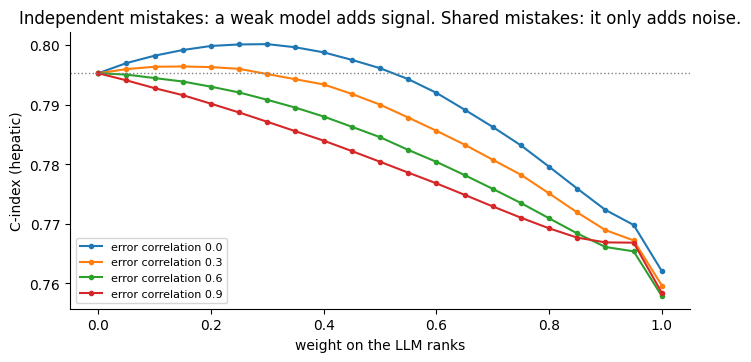

In [9]:
for shared, c in curves.items():
    plt.plot(W, c, marker=".", label=f"error correlation {shared:.1f}")
plt.axhline(curves[0.0][0], ls=":", c="grey", lw=1)
plt.xlabel("weight on the LLM ranks"); plt.ylabel("C-index (hepatic)"); plt.legend(fontsize=8)
plt.title("Independent mistakes: a weak model adds signal. Shared mistakes: it only adds noise.")
plt.show()

**Transfer:** judge a candidate member by what it adds **to the ensemble**, not by its
standalone score. A standalone gate would have thrown the LLM away.

## 6 · Check orthogonality before spending API calls
Scoring every patient costs two LLM calls each. Two cheap diagnostics, both printed by our
blend script, say early whether a new ranker is worth it:
- **Spearman ρ** between its ranks and the base ranks: lower means more new information.
- **Unique values:** a ranker with a handful of distinct scores ties most pairs.

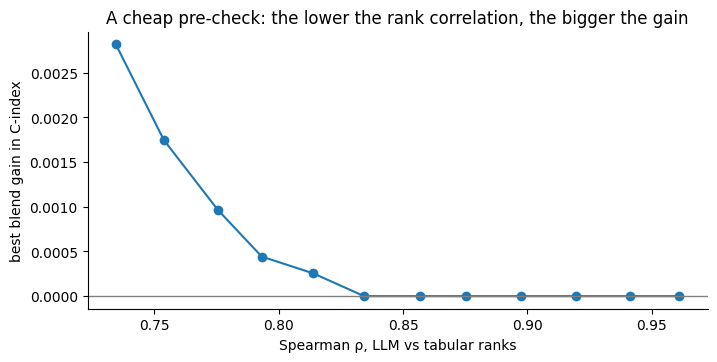

  5 levels:   6 unique of 2000, LLM alone C = 0.743
 20 levels:  21 unique of 2000, LLM alone C = 0.751
100 levels: 101 unique of 2000, LLM alone C = 0.752


In [10]:
rows = []
for shared in np.linspace(0, 0.95, 12):
    tab, llm = S.rankers(truth, seed=11, shared=shared)
    best = max(cidx(ev, t, (1 - w) * _rank01(tab) + w * _rank01(llm)) for w in W)
    rows.append((spearmanr(tab, llm)[0], best - cidx(ev, t, tab)))
rho, gain = zip(*rows)
plt.plot(rho, gain, marker="o"); plt.axhline(0, c="grey", lw=1)
plt.xlabel("Spearman ρ, LLM vs tabular ranks"); plt.ylabel("best blend gain in C-index")
plt.title("A cheap pre-check: the lower the rank correlation, the bigger the gain"); plt.show()
for levels in (5, 20, 100):
    _, llm = S.rankers(truth, seed=11, llm_levels=levels)
    print(f"{levels:3d} levels: {len(np.unique(llm)):3d} unique of {len(llm)}, LLM alone C = {cidx(ev, t, llm):.3f}")

## 7 · The blend we submitted: two stages
1. **Stage 1:** an EfficientNet-B0 image and tabular model (Cox loss, SGD) blended 50/50 in rank
   space with the split-endpoint GPT-OSS scores.
2. **Stage 2:** the 10-seed XGBoost + CatBoost base, with stage 1 at weight 0.15.

Both stages are rank blends, so the LLM's effective weight is small:

In [11]:
w1, w2 = 0.50, 0.15                                  # the weights in the README's reproduce steps
print(f"effective rank weights: base {1 - w2:.3f} | EfficientNet {w2 * (1 - w1):.3f} | GPT-OSS {w2 * w1:.3f}")

# The same recipe on synthetic rankers: base strong, image model medium, LLM weak and independent.
rng = np.random.default_rng(5)
base_r = truth + 0.6 * rng.normal(size=len(truth))
img_r = truth + 0.9 * (0.5 * (base_r - truth) / 0.6 + np.sqrt(0.75) * rng.normal(size=len(truth)))
_, llm_r = S.rankers(truth, seed=5, shared=0.1)
stage1 = (1 - w1) * _rank01(img_r) + w1 * _rank01(llm_r)
final = (1 - w2) * _rank01(base_r) + w2 * _rank01(stage1)
for name, s in (("base", base_r), ("image", img_r), ("LLM", llm_r), ("stage 1", stage1), ("final", final)):
    print(f"{name:8s} C = {cidx(ev, t, s):.4f}")

effective rank weights: base 0.850 | EfficientNet 0.075 | GPT-OSS 0.075
base     C = 0.7886
image    C = 0.7733
LLM      C = 0.7699
stage 1  C = 0.7739
final    C = 0.7922


In [12]:
from IPython.display import Markdown
if cv or lb:
    md = "| source | model | score |\n|---|---|---|\n"
    label = {"cv": "10-fold CV, as run", "cv_clean": "10-fold CV, window-free", "proxy": "CV leak probe"}
    md += "".join(f"| {label.get(r['stage'], r['stage'])} | {r['model']} | {float(r['weighted']):.4f} |\n" for r in cv)
    md += "".join(f"| leaderboard | {r['submission']} | {float(r['public_score']):.4f} |\n" for r in lb)
    note = ("\n*CV as run reads follow-up length, a leak that section 8 dissects. The window-free rows"
            " drop every feature computed over the observation window.*") if cv else ""
    display(Markdown("**Our real numbers**\n\n" + md + note))
else:
    display(Markdown("*Real numbers appear here after `python talk/export_scores.py` has run on the "
                     "challenge data. Leaderboard scores go in `talk/data/leaderboard.csv`.*"))

**Our real numbers**

| source | model | score |
|---|---|---|
| 10-fold CV, as run | xgb (10 seeds) | 0.9434 |
| 10-fold CV, as run | cat (10 seeds) | 0.9494 |
| 10-fold CV, as run | xgb + cat rank blend | 0.9502 |
| 10-fold CV, window-free | xgb (10 seeds), window-free | 0.9123 |
| 10-fold CV, window-free | cat (10 seeds), window-free | 0.8782 |
| 10-fold CV, window-free | xgb + cat rank blend, window-free | 0.9020 |
| CV leak probe | follow-up span alone (leak probe) | 0.9614 |
| cv_helm | window-free base | 0.9020 |
| cv_helm | GPT-OSS HeLM alone, window-free text | 0.7465 |
| cv_helm | base + GPT-OSS at weight 0.07 | 0.8999 |
| cv_helm_nemotron_joint | window-free base | 0.9020 |
| cv_helm_nemotron_joint | GPT-OSS HeLM alone, window-free text | 0.7889 |
| cv_helm_nemotron_joint | base + GPT-OSS at weight 0.07 | 0.9029 |
| cv_helm_medgemma_split | window-free base | 0.9020 |
| cv_helm_medgemma_split | GPT-OSS HeLM alone, window-free text | 0.5897 |
| cv_helm_medgemma_split | base + GPT-OSS at weight 0.07 | 0.8981 |
| cv_helm_medgemma_joint | window-free base | 0.9020 |
| cv_helm_medgemma_joint | GPT-OSS HeLM alone, window-free text | 0.6158 |
| cv_helm_medgemma_joint | base + GPT-OSS at weight 0.07 | 0.8993 |
| leaderboard | Tabular base: 10-seed XGB AFT + CatBoost (alone) | 0.8938 |
| leaderboard | Claude Haiku HeLM (alone) | 0.7528 |
| leaderboard | Tabular base + Haiku HeLM at weight 0.05 | 0.8983 |
| leaderboard | EfficientNet-B0 Cox fine-tune (alone) | 0.8443 |
| leaderboard | Tabular base + EfficientNet-B0 at weight 0.02 | 0.8966 |
| leaderboard | GPT-OSS 120B split-endpoint HeLM (alone) | 0.7919 |
| leaderboard | EfficientNet base + GPT-OSS HeLM at weight 0.07 | 0.9022 |
| leaderboard | Final two-stage: base + (EfficientNet + GPT-OSS split) | 0.9036 |

*CV as run reads follow-up length, a leak that section 8 dissects. The window-free rows drop every feature computed over the observation window.*

## 8 · Gates that say yes too easily
A **false-positive gate** declares a change real when it is not. Our gate was the public
leaderboard, and it is **deterministic**: re-uploading a file gives the identical score. So the
risk is not measurement noise. It is overfitting a fixed sample of **127 patients** (30% of 423).

A change passes only if it clears all five criteria:
1. **Resolution:** the gain beats 2 paired standard errors on the gate's own sample.
2. **Multiplicity:** it beats the best of K null tries, about SE·√(2 ln K).
3. **Mechanism:** it is no larger than error independence can deliver.
4. **Ceiling:** the score stays below what is attainable.
5. **Replication:** it shows up on independent evidence.

In [13]:
import gates as G
N_TEST, N_PUBLIC = 423, round(0.3 * 423)
stats = csv_rows("cohort_stats.csv")                 # aggregate event counts, once exported
if stats:
    RATES = {r["endpoint"]: float(r["events"]) / float(r["n_patients"]) for r in stats}
    RATE_SRC = "measured on the training set"
else:
    RATES, RATE_SRC = {"hep": 0.10, "death": 0.08}, "assumed"
CEILING = 0.95                   # calibration ceiling for the noise model
RED_FLAG = 0.947                 # the repo's own rule: CV above this is treated as a leak
CAL = {ep: G.calibration_cohort(CEILING, event_rate=RATES[ep]) for ep in RATES}
sig = lambda c: G.sigma_from_c(CAL["hep"], c)        # C-index -> noise sd of a ranker
def weighted_se(s_a, s_c, w, r=0.3, n=N_PUBLIC):
    """Paired SE of the 0.7/0.3 metric's gain, endpoints treated as independent."""
    se = {ep: G.paired_delta(CAL[ep], s_a, s_c, w, r, n)[1] for ep in CAL}
    return float(np.sqrt(0.49 * se["hep"] ** 2 + 0.09 * se["death"] ** 2))

### 1 · Resolution: how small a gain can 127 patients see?

In [14]:
n_ev = round(RATES["hep"] * N_PUBLIC)
print(f"event rates {RATE_SRC}: hepatic {RATES['hep']:.0%}, death {RATES['death']:.0%}"
      f" -> about {n_ev} hepatic events in the public sample")
print(f"one C-index of 0.89 (Hanley-McNeil): SE = {G.hanley_mcneil_se(0.89, n_ev, N_PUBLIC - n_ev):.3f}")
s_base, s_oss = sig(0.8967), sig(0.7919)
print("paired SE of a GPT-OSS-style blend gain (weight 0.07), weighted metric:")
for name, n in (("public", N_PUBLIC), ("private", N_TEST - N_PUBLIC), ("whole test", N_TEST)):
    se = weighted_se(s_base, s_oss, 0.07, n=n)
    print(f"  {name:10s} n = {n:3d}: SE {se:.4f}, credible gain {2 * se:.4f}")

event rates measured on the training set: hepatic 4%, death 8% -> about 5 hepatic events in the public sample
one C-index of 0.89 (Hanley-McNeil): SE = 0.097


paired SE of a GPT-OSS-style blend gain (weight 0.07), weighted metric:
  public     n = 127: SE 0.0056, credible gain 0.0111


  private    n = 296: SE 0.0029, credible gain 0.0059


  whole test n = 423: SE 0.0024, credible gain 0.0048


A paired difference is far tighter than a single score. With about five hepatic events in the
public sample, a credible gain still needs **about 0.01**.

### 2 · Multiplicity: the best of many tries looks good by construction

In [15]:
se_ref = weighted_se(s_base, s_oss, 0.07)
for k in (5, 30, 272):
    print(f"K = {k:3d} tries on one sample -> typical best null gain {G.null_max_gain(se_ref, k):.4f}")

# 30 near-tied submissions, ranked on a 127-patient public split, judged on the other 296.
z, ev_c, t_c = CAL["hep"]
rng = np.random.default_rng(8); s_top = sig(0.93)
core = z + s_top * rng.normal(size=len(z))
subs = [core + 0.3 * s_top * rng.normal(size=len(z)) for _ in range(30)]
hits, optimism = 0, []
while len(optimism) < 100:
    idx = rng.choice(len(z), N_TEST, replace=False); pub, prv = idx[:N_PUBLIC], idx[N_PUBLIC:]
    if not ev_c[pub].any():                          # an event-free public split cannot be scored
        continue
    c_pub = [cidx(ev_c[pub], t_c[pub], s[pub]) for s in subs]
    c_prv = [cidx(ev_c[prv], t_c[prv], s[prv]) for s in subs]
    k = int(np.argmax(c_pub)); hits += k == int(np.argmax(c_prv)); optimism.append(c_pub[k] - c_prv[k])
print(f"\npublic winner is also the private winner in {hits}% of splits;"
      f" its public score is inflated by {np.mean(optimism):+.4f} on average")

K =   5 tries on one sample -> typical best null gain 0.0100
K =  30 tries on one sample -> typical best null gain 0.0145
K = 272 tries on one sample -> typical best null gain 0.0186



public winner is also the private winner in 5% of splits; its public score is inflated by +0.0098 on average


**Real case:** the platform marked `submission (7)` best public at 0.9308 and
`new_rank_ensemble` best private, listed at 0.9301. We uploaded 272 times, so the public
winner being the wrong pick is the expected outcome, not bad luck.

### 3 · Mechanism: how much gain can complementarity deliver?
Model each ranker as truth plus noise of sd *s*. For two rankers with error correlation *r*,
the best blend puts value weight **(s₁² − r s₁s₂) / (s₁² + s₂² − 2r s₁s₂)** on the second, and
its noise variance is **s₁²s₂²(1 − r²) / (s₁² + s₂² − 2r s₁s₂)**. Each standalone C-index fixes
its *s*. First we check the formula against simulation.

*Assumptions: a ceiling C-index of 0.95 maps each score to a noise level, and the weighted
metric is treated as one endpoint.*

In [16]:
cal_syn = (C.true_hep.to_numpy(), C.hep_event.to_numpy(), C.hep_time.to_numpy())
ev_s, t_s = cal_syn[1], cal_syn[2]
for shared in (0.0, 0.3, 0.6):
    tab, llm = S.rankers(cal_syn[0], seed=7, shared=shared)
    s1, s2 = G.sigma_from_c(cal_syn, cidx(ev_s, t_s, tab)), G.sigma_from_c(cal_syn, cidx(ev_s, t_s, llm))
    simulated = max(cidx(ev_s, t_s, (1 - w) * _rank01(tab) + w * _rank01(llm)) for w in W) - cidx(ev_s, t_s, tab)
    predicted, w_star = G.predicted_gain(cal_syn, s1, s2, shared)
    print(f"error corr {shared:.1f}: predicted best gain {predicted:+.4f} at w = {w_star:.2f}"
          f" | simulated {simulated:+.4f}")

error corr 0.0: predicted best gain +0.0064 at w = 0.29 | simulated +0.0049


error corr 0.3: predicted best gain +0.0020 at w = 0.19 | simulated +0.0011


error corr 0.6: predicted best gain +0.0000 at w = 0.00 | simulated +0.0000


The formula tracks the simulation and overstates it by about 0.001. The coarse LLM scores add
ties that the Gaussian model does not describe. So the predicted gain is an **upper bound**.

Haiku into base: observed +0.0046 | predicted at w = 0.05 with independent errors +0.0023


GPT-OSS into EfficientNet base: observed +0.0056 | predicted at w = 0.07 with independent errors +0.0037


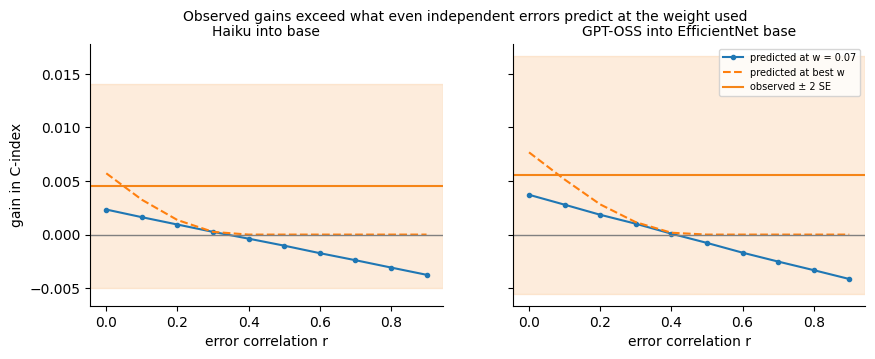

In [17]:
cases = (("Haiku into base", 0.8938, 0.7528, 0.05, 0.89834 - 0.89379),
         ("GPT-OSS into EfficientNet base", 0.8967, 0.7919, 0.07, 0.90223 - 0.89665))
R = np.linspace(0, 0.9, 10)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (name, c_a, c_b, w, seen) in zip(axs, cases):
    s1, s2 = sig(c_a), sig(c_b)
    ax.plot(R, [G.predicted_gain(CAL["hep"], s1, s2, r, w)[0] for r in R], marker=".", label=f"predicted at w = {w}")
    ax.plot(R, [G.predicted_gain(CAL["hep"], s1, s2, r)[0] for r in R], ls="--", label="predicted at best w")
    se = weighted_se(s1, s2, w)
    print(f"{name}: observed {seen:+.4f} | predicted at w = {w} with independent errors"
          f" {G.predicted_gain(CAL['hep'], s1, s2, 0.0, w)[0]:+.4f}")
    ax.axhspan(seen - 2 * se, seen + 2 * se, color="#f58518", alpha=0.15)
    ax.axhline(seen, color="#f58518", label="observed ± 2 SE")
    ax.axhline(0, c="grey", lw=1); ax.set_title(name, fontsize=10); ax.set_xlabel("error correlation r")
axs[0].set_ylabel("gain in C-index"); axs[1].legend(fontsize=7)
plt.suptitle("Observed gains exceed what even independent errors predict at the weight used", fontsize=10)
plt.show()

At the weights we used, both observed gains are **larger than the prediction even at r = 0**,
as printed above. Independence cannot explain all of either gain. The rest is most likely noise
from the 127-patient sample.

### 4 · Ceiling and 5 · Replication
**Ceiling.** A score above what is attainable is a leak, not a win. Compare against the true
risk in simulation, a baseline-only model, or a red-flag threshold. Section 2 showed a model at
0.914 against a true risk of 0.825. `ablation_finetune_efficientnet.py` flags CV above 0.947.

**Replication.** A gain must show up on evidence the gate never saw: CV folds, the other
endpoint, or a held-out split. A sign test across folds is cheap.

In [18]:
cv_by = {r["model"]: r for r in cv}
lb_base = float(lb[0]["public_score"]) if lb else float("nan")
if "xgb + cat rank blend" in cv_by:
    c_cv = float(cv_by["xgb + cat rank blend"]["weighted"])
    probe = cv_by.get("follow-up span alone (leak probe)")
    print(f"tabular base: 10-fold CV {c_cv:.4f} | public leaderboard {lb_base:.4f} | gap {c_cv - lb_base:+.4f}")
    print(f"red flag {RED_FLAG}: CV is {'ABOVE' if c_cv > RED_FLAG else 'below'} it")
    clean = cv_by.get("xgb + cat rank blend, window-free")
    if clean:
        print(f"same base, window-free features: CV {float(clean['weighted']):.4f}"
              f" | gap to leaderboard {float(clean['weighted']) - lb_base:+.4f}")
    if probe:
        print(f"leak probe, follow-up span alone: CV {float(probe['weighted']):.4f}"
              f" (hepatic {float(probe['c_hep']):.3f}, death {float(probe['c_death']):.3f})")
    nh, nd = round(RATES["hep"] * N_PUBLIC), round(RATES["death"] * N_PUBLIC)
    se_one = np.sqrt(0.49 * G.hanley_mcneil_se(lb_base, nh, N_PUBLIC - nh) ** 2
                     + 0.09 * G.hanley_mcneil_se(lb_base, nd, N_PUBLIC - nd) ** 2)
    print(f"one public score's SE ~ {se_one:.3f}, so a CV-to-leaderboard gap under"
          f" {2 * se_one:.3f} proves nothing by itself")
    n_hep = next((float(r["events"]) for r in stats if r["endpoint"] == "hep"), None) if stats else None
    if n_hep:
        k = round(n_hep / 10); print(f"about {k} hepatic events per CV fold: one fold's SE ~"
                                     f" {G.hanley_mcneil_se(0.96, k, 125 - k):.3f}")
else:
    print("run talk/export_scores.py on the challenge data to fill this slide")

tabular base: 10-fold CV 0.9502 | public leaderboard 0.8938 | gap +0.0564
red flag 0.947: CV is ABOVE it
same base, window-free features: CV 0.9020 | gap to leaderboard +0.0082
leak probe, follow-up span alone: CV 0.9614 (hepatic 0.958, death 0.969)
one public score's SE ~ 0.070, so a CV-to-leaderboard gap under 0.140 proves nothing by itself
about 5 hepatic events per CV fold: one fold's SE ~ 0.062


**Our CV was a false-positive gate.** The follow-up span alone outscores the whole model, so the
model is mostly reading how long patients were followed. The CV also sits above the repo's own red
flag. The leaderboard gap alone could not show this: one public score is too noisy. The leak
probe and the ceiling did. With about five events per fold, a perfect fold of 1.000 is noise too.

**The fix:** drop every feature computed over the observation window, 26 in all. The same base
then scores **0.902** in CV, below the red flag and close to the leaderboard's 0.894.

### Another decision the leaky gate approved: the 50/50 blend
The pipeline blends XGBoost and CatBoost 50/50 because the CV as run favoured it. Without the
leak, XGBoost alone looks better. Is that a finding, or a second false positive?

In [19]:
by = {(r["stage"], r["model"]): float(r["weighted"]) for r in cv}
for stage, sfx, label in (("cv", "", "CV as run"), ("cv_clean", ", window-free", "window-free CV")):
    vals = [by.get((stage, m + sfx)) for m in ("xgb (10 seeds)", "cat (10 seeds)", "xgb + cat rank blend")]
    if all(v is not None for v in vals):
        print(f"{label:15s} XGB {vals[0]:.4f} | Cat {vals[1]:.4f} | blend {vals[2]:.4f}")
wf = [r for r in csv_rows("cv_folds.csv") if r["comparison"] == "xgb_only_vs_blend"]
if wf:
    d = {ep: np.array([float(r["delta"]) for r in wf if r["endpoint"] == ep]) for ep in ("hep", "death")}
    for ep, name in (("hep", "hepatic"), ("death", "death")):
        k = int((d[ep] > 0).sum())
        print(f"XGB beats blend in {k}/10 {name} folds (p = {binomtest(k, 10, 0.5, alternative='greater').pvalue:.2f})")
    wd = 0.7 * d["hep"] + 0.3 * d["death"]
    views = [("fold mean", wd.mean(), wd.std(ddof=1) / np.sqrt(len(wd)))]
    boot = {r["comparison"]: r for r in csv_rows("cv_tests.csv")}.get("xgb_only_vs_blend")
    if boot:
        views.append(("patient bootstrap", float(boot["estimate"]), float(boot["se"])))
    for name, est, se in views:              # K = 3: picked among XGB, Cat and blend after seeing CV
        print(f"{name:17s} {est:+.4f} ± {se:.4f} ({est / se:.1f} SE) -> {G.verdict(est, se, 3, np.inf, False)}")

CV as run       XGB 0.9434 | Cat 0.9494 | blend 0.9502
window-free CV  XGB 0.9123 | Cat 0.8782 | blend 0.9020
XGB beats blend in 6/10 hepatic folds (p = 0.38)
XGB beats blend in 5/10 death folds (p = 0.62)
fold mean         +0.0155 ± 0.0056 (2.8 SE) -> unreplicated
patient bootstrap +0.0103 ± 0.0070 (1.5 SE) -> within noise


**Suggestive, not yet credible.** The leaky CV approved 50/50 on a margin of 0.0008. Without
the leak, XGBoost looks better, but the evidence is mixed: the fold mean clears the bars, the
patient bootstrap does not, and XGBoost wins only about half the folds. We also picked this
comparison after seeing the scores. Confirm it on data the choice never saw before switching.

### A cheap replication check

In [20]:
tab, llm = S.rankers(cal_syn[0], seed=21, shared=0.1)
folds = np.array_split(np.random.default_rng(21).permutation(len(tab)), 10)
blend = 0.93 * _rank01(tab) + 0.07 * _rank01(llm)
d = [cidx(ev_s[f], t_s[f], blend[f]) - cidx(ev_s[f], t_s[f], tab[f]) for f in folds]
k = sum(x > 0 for x in d)
print(f"blend beats base in {k} of 10 folds; sign-test p = {binomtest(k, 10, 0.5, alternative='greater').pvalue:.3f}")

blend beats base in 9 of 10 folds; sign-test p = 0.011


### The real replication: GPT-OSS inside the window-free CV
GPT-OSS scored all 1,253 training patients zero-shot. Its text drops follow-up length and
post-event visits, like the base. The blend weight, **0.07**, is the submitted one, fixed in advance.

In [21]:
helm = {r["model"]: r for r in cv if r["stage"] == "cv_helm"}
fold_rows = [r for r in csv_rows("cv_folds.csv") if r["comparison"] == "helm_blend_vs_base"]
if helm:
    short = {"window-free base": "base", "GPT-OSS HeLM alone, window-free text": "GPT-OSS alone",
             "base + GPT-OSS at weight 0.07": "base + GPT-OSS"}
    for name, r in helm.items():
        print(f"{short.get(name, name):15s} {float(r['weighted']):.4f}"
              f" (hep {float(r['c_hep']):.3f}, death {float(r['c_death']):.3f})")
    for ep, name in (("hep", "hepatic"), ("death", "death")):
        d = np.array([float(r["delta"]) for r in fold_rows if r["endpoint"] == ep])
        k = int((d > 0).sum())
        print(f"{name:8s} blend wins {k}/{len(d)} folds, mean {d.mean():+.4f}"
              f" ± {d.std(ddof=1) / np.sqrt(len(d)):.4f}")
    b, l = float(helm["window-free base"]["weighted"]), float(helm["GPT-OSS HeLM alone, window-free text"]["weighted"])
    s_b, s_l = sig(b), sig(l)
    print("predicted gain: " + " | ".join(
        f"r={r} {G.predicted_gain(CAL['hep'], s_b, s_l, r, 0.07)[0]:+.4f}" for r in (0.0, 0.3, 0.5)))
else:
    print("run talk/helm_train_scores.py, then talk/helm_cv.py, to fill this slide")

base            0.9020 (hep 0.904, death 0.898)
GPT-OSS alone   0.7465 (hep 0.752, death 0.733)
base + GPT-OSS  0.8999 (hep 0.903, death 0.894)
hepatic  blend wins 1/10 folds, mean -0.0045 ± 0.0043
death    blend wins 2/10 folds, mean -0.0015 ± 0.0021


predicted gain: r=0.0 +0.0024 | r=0.3 -0.0002 | r=0.5 -0.0021


**It does not replicate.** The blend loses in most folds, as the mechanism predicts if the errors
correlate near 0.5. *Not an exact replay: window-free text, stricter masking, tabular base.*

### One prompt or two? Joint prediction of both endpoints
The split prompts ask about each endpoint alone. A joint prompt asks for both risks at once, so
the model can reason about competing risks. Same text, same weight 0.07, same folds. GPT-OSS and
MedGemma 1.5 run with thinking off; Nemotron 3 Super runs with reasoning on.

In [22]:
tests = {r["comparison"]: r for r in csv_rows("cv_tests.csv")}
runs = [("GPT-OSS split", "cv_helm", "helm_blend_vs_base"), ("GPT-OSS joint", "cv_helm_joint", "helm_joint_blend_vs_base")]
runs += [(f"{label} {mode}", f"cv_helm_{name}_{mode}", f"helm_{name}_{mode}_blend_vs_base")
         for name, label in (("nemotron", "Nemotron"), ("medgemma", "MedGemma")) for mode in ("split", "joint")]
shown = 0
for label, stage, key in runs:
    r = {x["model"]: float(x["weighted"]) for x in cv if x["stage"] == stage}
    if r and key in tests:
        est, se = float(tests[key]["estimate"]), float(tests[key]["se"])
        print(f"{label:14s} alone {r['GPT-OSS HeLM alone, window-free text']:.3f} | gain {est:+.4f} ± {se:.4f}")
        shown += 1
for key, label in (("helm_joint_vs_split_blend", "GPT-OSS joint - split"),
                   ("helm_nemotron_joint_vs_split_blend", "Nemotron joint - split"),
                   ("helm_medgemma_joint_vs_split_blend", "MedGemma joint - split")):
    if key in tests:
        est, se = float(tests[key]["estimate"]), float(tests[key]["se"])
        print(f"{label:22s} {est:+.4f} ± {se:.4f}")
if shown <= 1:
    print("run talk/helm_train_scores.py for the joint, Nemotron and MedGemma variants, then talk/helm_cv.py")

GPT-OSS split  alone 0.747 | gain -0.0018 ± 0.0020
Nemotron joint alone 0.789 | gain +0.0010 ± 0.0017
MedGemma split alone 0.590 | gain -0.0038 ± 0.0022
MedGemma joint alone 0.616 | gain -0.0025 ± 0.0025
MedGemma joint - split +0.0013 ± 0.0018


**No model or prompt clears the noise.** Reasoning helps the LLM alone: Nemotron with reasoning
on is the strongest, and the only blend with a positive point estimate. But it wins only 4 of 10
folds on each endpoint. The LLMs also agree with each other (rank correlation about 0.8) far more
than with the base, so swapping one LLM for another changes little of what it adds. For MedGemma,
the joint prompt is no better than split, within noise.

### The scorecard: our own leaderboard decisions

In [23]:
# (decision, gain seen, K tries for that decision in the upload history, base C, added-model C, weight)
decisions = [("Haiku HeLM into base", 0.89834 - 0.89379, 8, 0.8938, 0.7528, 0.05),
             ("EfficientNet into base", 0.89665 - 0.89379, 6, 0.8938, 0.8443, 0.02),
             ("GPT-OSS into EfficientNet base", 0.90223 - 0.89665, 5, 0.8967, 0.7919, 0.07),
             ("Final two-stage over GPT-OSS w 0.07", 0.90364 - 0.90223, 2, None, None, None),
             ("Final two-stage over tabular base", 0.90364 - 0.89379, 60, None, None, None),
             ("Best public over best private", 0.93081 - 0.93006, 272, None, None, None)]
md = "| decision | gain | SE | gain / SE | K | bar after K | mechanism max | verdict |\n|---|---|---|---|---|---|---|---|\n"
for name, gain, k, c_a, c_b, w in decisions:
    if c_a:
        s1, s2 = sig(c_a), sig(c_b)
        se, mech = weighted_se(s1, s2, w), G.predicted_gain(CAL["hep"], s1, s2, 0.0)[0]
    else:
        se, mech = se_ref, np.inf                  # no mechanism model: generic paired SE
    v = G.verdict(gain, se, k, mech, replicated=False)
    rep = {r["comparison"]: r for r in csv_rows("cv_tests.csv")}.get("helm_blend_vs_base")
    if name.startswith("GPT-OSS") and rep and float(rep["estimate"]) <= 0:
        v = "failed replication in CV"
    mech_txt = "n/a" if np.isinf(mech) else f"{mech:+.4f}"
    md += (f"| {name} | {gain:+.4f} | {se:.4f} | {gain / se:.1f} | {k} | {G.null_max_gain(se, k):.4f}"
           f" | {mech_txt} | **{v}** |\n")
display(Markdown(md))

| decision | gain | SE | gain / SE | K | bar after K | mechanism max | verdict |
|---|---|---|---|---|---|---|---|
| Haiku HeLM into base | +0.0046 | 0.0048 | 1.0 | 8 | 0.0097 | +0.0057 | **within noise** |
| EfficientNet into base | +0.0029 | 0.0019 | 1.5 | 6 | 0.0037 | +0.0144 | **within noise** |
| GPT-OSS into EfficientNet base | +0.0056 | 0.0056 | 1.0 | 5 | 0.0100 | +0.0077 | **failed replication in CV** |
| Final two-stage over GPT-OSS w 0.07 | +0.0014 | 0.0056 | 0.3 | 2 | 0.0065 | n/a | **within noise** |
| Final two-stage over tabular base | +0.0099 | 0.0056 | 1.8 | 60 | 0.0159 | n/a | **within noise** |
| Best public over best private | +0.0008 | 0.0056 | 0.1 | 272 | 0.0186 | n/a | **within noise** |


**The honest reading:** with real event rates, every leaderboard decision falls within noise,
and the one we could replicate failed. Our CV as run failed the ceiling check, and the
window-free CV passes it. The weak-ranker mechanism is real. Here, the LLM's errors were too
close to the base's for it to help.

## 9 · Limits and honest reporting
- **Uncalibrated:** the LLM scores rank patients. They are not risks, and are never reported as such.
- **Cost and drift:** two calls per patient, and a hosted model can change under you. Store the
  raw scores and the model tag with each run.
- **Replicated and failed:** scored on the training set, GPT-OSS at weight 0.07 slightly lowers
  the leak-free CV. Its leaderboard gain was noise on 127 patients.
- **Small gate:** 127 public patients hold only a handful of hepatic events, so they resolve
  only gains larger than most of ours.
- **Leaky CV:** the pipeline's CV reads follow-up length. Quote the window-free CV, 0.902, instead.

## Generalising the idea
| Setting | Strong base | Orthogonal ranker | Combine by |
|---|---|---|---|
| Clinical survival (this talk) | gradient-boosted AFT | LLM reading a clinical summary | rank blend |
| Credit or churn risk | boosted trees on tabular data | LLM over notes or transcripts | rank blend |
| Search and retrieval | a learned ranker | an LLM relevance judge | reciprocal rank fusion |
| Triage and alerting | rules and thresholds | an LLM reading free-text reports | ordered escalation |

## Takeaways for Ghanaian researchers
- **Start with a model you can run yourself.** MedGemma 1.5 (3.3 GB) scored all 1,253 patients on
  a laptop in about 35 minutes, and no record left the machine.
- **Test cheaply before you pay.** Score three patients first, then check rank correlation with your
  model and the number of distinct scores. Free API tiers allow about 1,000 requests a day, so plan
  runs around them and save after every call.
- **Judge an LLM by what it adds to your model,** on your own held-out data, not by one leaderboard.
  127 patients could not tell our gain from noise.
- **Look for leaks in your own features first.** Here, the gap between first and last visit ages
  alone scored 0.96.
- **Know where your data goes.** Cloud and free endpoints may log prompts, so check the data terms
  before sending patient records.

## The checklist
- [ ] Is the metric a ranking metric? Then blend ranks, not raw scores.
- [ ] Did I drop label proxies and mask data recorded after the event?
- [ ] Does the serialized text carry trajectories and thresholds, not only last values?
- [ ] Is each endpoint asked separately?
- [ ] Is the candidate judged by its gain **in the ensemble**, not alone?
- [ ] Did I check rank correlation and unique values before paying for every call?
- [ ] Were blend weights fixed on a coarse grid and confirmed on held-out data?
- [ ] Does the gain beat 2 paired SEs on the gate's sample, and the bar for K tries?
- [ ] Is the gain no larger than error independence can deliver?
- [ ] Is every number labelled measured, leaderboard or synthetic?